In [10]:
from dotenv import load_dotenv
load_dotenv()

import uuid
from typing import List
from pydantic import BaseModel, Field

from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage
from langchain_core.runnables import RunnableConfig

from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.store.memory import InMemoryStore
from langgraph.store.base import BaseStore

In [11]:
store = InMemoryStore()

In [12]:
SYSTEM_PROMPT_TEMPLATE = """You are a helpful assistant with memory capabilities.
If user-specific memory is available, use it to personalize 
your responses based on what you know about the user.

Your goal is to provide relevant, friendly, and tailored 
assistance that reflects the user’s preferences, context, and past interactions.

If the user’s name or relevant personal context is available, always personalize your responses by:
    – Always Address the user by name (e.g., "Sure, Nitish...") when appropriate
    – Referencing known projects, tools, or preferences (e.g., "your MCP server python based project")
    – Adjusting the tone to feel friendly, natural, and directly aimed at the user

Avoid generic phrasing when personalization is possible.

Use personalization especially in:
    – Greetings and transitions
    – Help or guidance tailored to tools and frameworks the user uses
    – Follow-up messages that continue from past context

Always ensure that personalization is based only on known user details and not assumed.

In the end suggest 3 relevant further questions based on the current response and user profile

The user’s memory (which may be empty) is provided as: {user_details_content}
"""

In [13]:
memory_llm= ChatGroq(model="openai/gpt-oss-120b")

In [14]:
class MemoryItem(BaseModel):
    text: str = Field(description="Atomic user memory")
    is_new: bool = Field(description="True if new, false if duplicate")

In [15]:
class MemoryDecision(BaseModel):
    should_write: bool
    memories: List[MemoryItem] = Field(default_factory=list)

In [16]:
memory_extractor = memory_llm.with_structured_output(MemoryDecision)

In [17]:
MEMORY_PROMPT = """You are responsible for updating and maintaining accurate user memory.

CURRENT USER DETAILS (existing memories):
{user_details_content}

TASK:
- Review the user's latest message.
- Extract user-specific info worth storing long-term (identity, stable preferences, ongoing projects/goals).
- For each extracted item, set is_new=true ONLY if it adds NEW information compared to CURRENT USER DETAILS.
- If it is basically the same meaning as something already present, set is_new=false.
- Keep each memory as a short atomic sentence.
- No speculation; only facts stated by the user.
- If there is nothing memory-worthy, return should_write=false and an empty list.
"""

In [18]:
def remember_node(state: MessagesState, config: RunnableConfig, *, store: BaseStore):
    user_id = config["configurable"]["user_id"]
    ns = ("user", user_id, "details")

    # existing memory
    items = store.search(ns)
    existing = "\n".join(it.value["data"] for it in items) if items else "(empty)"

    # last user message
    last_msg = state["messages"][-1].content

    decision: MemoryDecision = memory_extractor.invoke(
        [
            SystemMessage(content=MEMORY_PROMPT.format(user_details_content=existing)),
            {"role": "user", "content": last_msg},
        ]
    )

    if decision.should_write:
        for mem in decision.memories:
            if mem.is_new:
                store.put(ns, str(uuid.uuid4()), {"data": mem.text})

    return {}  # no message change

In [19]:
chat_llm= ChatGroq(model="openai/gpt-oss-120b")

In [20]:
def chat_node(state: MessagesState, config: RunnableConfig, *, store: BaseStore):
    user_id = config["configurable"]["user_id"]
    ns = ("user", user_id, "details")

    items = store.search(ns)
    user_details = "\n".join(it.value["data"] for it in items) if items else ""

    system_msg = SystemMessage(
        content=SYSTEM_PROMPT_TEMPLATE.format(
            user_details_content=user_details or "(empty)"
        )
    )

    response = chat_llm.invoke([system_msg] + state["messages"])
    return {"messages": [response]}

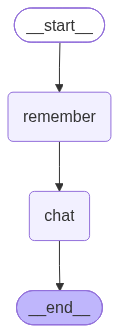

In [21]:
builder = StateGraph(MessagesState)
builder.add_node("remember", remember_node)
builder.add_node("chat", chat_node)

builder.add_edge(START, "remember")
builder.add_edge("remember", "chat")
builder.add_edge("chat", END)

graph = builder.compile(store=store)

graph

In [22]:
config = {"configurable": {"user_id": "u1"}}

In [23]:
result = graph.invoke({"messages": [{"role": "user", "content": "Hi, my name is shashank"}]}, config)
result['messages'][-1].content

'Hi Shashank! 👋  \n\nWhat can I help you with today? Whether it’s a coding question, a project you’re working on, or anything else, just let me know and we’ll dive right in.  \n\n---\n\n**Here are a few ideas to get us started:**\n\n1. Are you looking for assistance with a specific programming language or framework?  \n2. Do you have a project or task you’d like help planning or troubleshooting?  \n3. Would you like recommendations for tools, resources, or learning paths related to your interests?  '

In [24]:
result = graph.invoke({"messages": [{"role": "user", "content": "i build ai agents"}]}, config)
print(result['messages'][-1].content)

Sure, Shashank, it’s great to hear you’re building AI agents!  

If you’re looking for ideas or help with any part of the workflow—whether it’s designing the agent’s architecture, choosing the right language model, handling tool‑calling, or deploying at scale—just let me know what you’re focusing on right now. Here are a few quick pointers that often come in handy for AI‑agent projects:

| Area | Tips / Resources |
|------|-------------------|
| **Model selection** | • **OpenAI GPT‑4o** for multimodal reasoning<br>• **Claude 3.5 Sonnet** for cost‑effective, high‑quality output<br>• **Llama 3.1** if you need an open‑source option you can run locally |
| **Frameworks** | • **LangChain** or **LlamaIndex** for quick tool‑integration<br>• **AutoGPT** for self‑prompting loops<br>• **CrewAI** if you need multi‑agent collaboration |
| **Tool‑calling** | • Define clear function schemas (JSON) and use the model’s *function calling* feature.<br>• Test with the **OpenAI “functions”** endpoint or *

In [25]:
result = graph.invoke({"messages": [{"role": "user", "content": "Explain GenAI simply"}]}, config)
print(result['messages'][-1].content)

Sure, Shashank—let’s break down Generative AI (GenAI) in the simplest terms.

---

### 1️⃣ What GenAI Is  
**Generative AI** is a type of artificial intelligence that can **create new content**—like text, images, music, code, or even video—rather than just recognizing or classifying what already exists. Think of it as a very clever “artist” that has learned the patterns of a massive amount of existing work and can now produce its own.

### 2️⃣ How It Learns  
1. **Training Data** – The model is fed huge datasets (books, webpages, photos, code repositories, etc.).  
2. **Pattern Extraction** – Using deep neural networks (often transformer architectures), it learns statistical relationships: which words follow which, how objects look, how code structures flow, etc.  
3. **Fine‑tuning** – You can later adjust the model on a smaller, domain‑specific dataset (e.g., your own AI‑agent logs) so it generates content that matches your style or requirements.

### 3️⃣ What It Does When You Ask It 